
# Lab 7: Fast Fourier Transform (FFT)

In [5]:
import librosa
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

from scipy import integrate, interpolate
from os import path, getcwd

 **Example 1** : Chord - musical sound: Do mayor. Done in class.

![Do mayor](https://upload.wikimedia.org/wikipedia/commons/7/79/Major_chord_on_C.png)

Load the Nota_CM_piano.mp3 file from a Do mayor sound:
1. Do the FFT using scipy and Numpy rutines (see notebook)

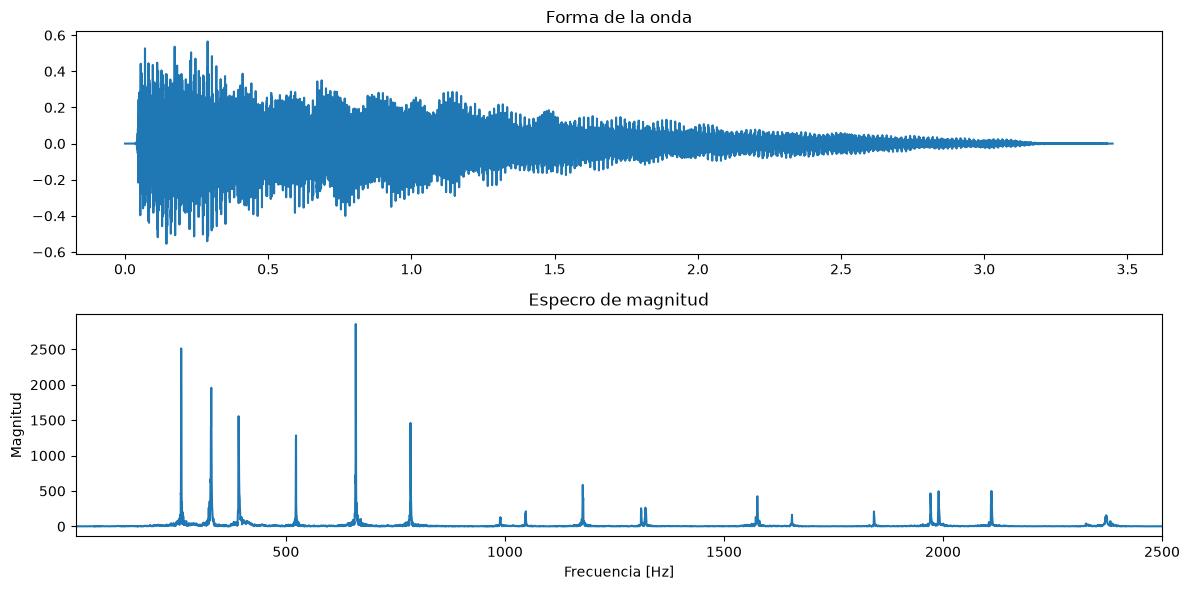

In [6]:
# Carpeta principal del proyecto (en mi caso comptational_physics)
project_root = path.abspath(path.join(getcwd(), "../.."))

# Lectura aduio para la fft
audio, sr = librosa.load(f"{project_root}/Sesiones/Fourier/Nota_CM_piano.mp3", sr=None)

# FFT usando numpy
N = len(audio)
fft_vals = np.fft.fft(audio)
fft_mag = np.abs(fft_vals[:N//2])      # solo frecuencias positivas
freqs = np.fft.fftfreq(N, 1/sr)[:N//2]

plt.figure(figsize=(12,6))

plt.subplot(2,1,1)
plt.plot(np.linspace(0, N/sr, N), audio)
plt.title("Forma de la onda")

plt.subplot(2,1,2)
plt.plot(freqs, fft_mag)
plt.title("Especro de magnitud")
plt.xlabel("Frecuencia [Hz]")
plt.ylabel("Magnitud")
plt.xlim(20, 2500)  # seleccionando solamente las frecuencias principales
plt.tight_layout()
plt.show()

2. Used the rutine created in class `FT(x,y)`. Modify it and do the FT to the signal. Do you get the same results?

Calculando la transformada de Fourier:   0%|          | 0/5000 [00:00<?, ?it/s]/tmp/ipykernel_18103/2682186658.py:33: IntegrationWarning: The integral is probably divergent, or slowly convergent.
  Re = integrate.quad(lambda t: f_interp(t) * g(t, wi).real, a, b)[0] # parte real de la integral
/tmp/ipykernel_18103/2682186658.py:34: IntegrationWarning: The integral is probably divergent, or slowly convergent.
  Im = integrate.quad(lambda t: f_interp(t) * g(t, wi).imag, a, b)[0] # parte imaginaria de la integral
Calculando la transformada de Fourier:   0%|          | 4/5000 [00:00<05:27, 15.24it/s]/tmp/ipykernel_18103/2682186658.py:34: IntegrationWarning: The maximum number of subdivisions (50) has been achieved.
  If increasing the limit yields no improvement it is advised to analyze 
  the integrand in order to determine the difficulties.  If the position of a 
  local difficulty can be determined (singularity, discontinuity) one will 
  probably gain from splitting up the interval and 

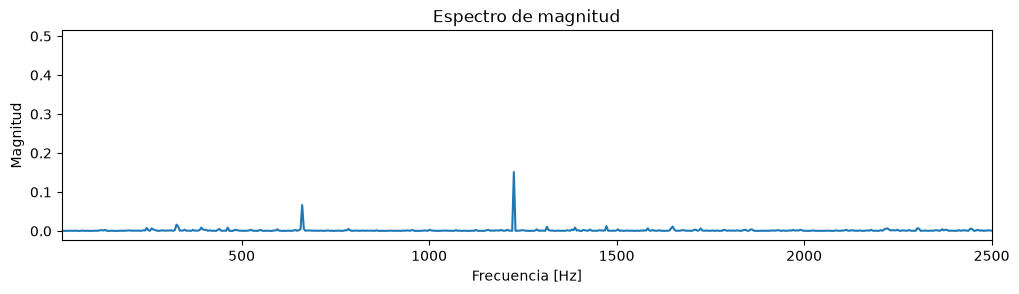

In [7]:
from tqdm import tqdm # usando tqdm para ver cuanto falta en los cálculos

# Función para la rutina creada en clase
def FT(f: np.array, w: np.array, a: float, b: float, sr: int) -> pd.DataFrame:
    """
    Calcula la transformada de Fourier de una señal f(t) en un rango de frecuencias w.
    Parámetros:
    f: np.array
        Señal de entrada en el dominio del tiempo.
    w: np.array
        Rango de frecuencias en el que se calculará la transformada.
    a: float
        Límite inferior del intervalo de integración.
    b: float
        Límite superior del intervalo de integración.
    sr: int
        Frecuencia de muestreo.

    Retorna:
    pd.DataFrame
        DataFrame con los resultados de la transformada de Fourier.
    """
    # Tiempo asociado a cada muestra
    t = np.arange(len(f)) / sr

    # Interpolación del audio (para obtener valores continuos de f(t))
    f_interp = interpolate.interp1d(t, f, kind="linear", bounds_error=False, fill_value=0)
    g = lambda t, w: np.exp(-1j * 2 * np.pi * w * t) # función compleja para la transformada de Fourier vista en el notebook

    datos = []

    for wi in tqdm(w, desc="Calculando la transformada de Fourier"):
        Re = integrate.quad(lambda t: f_interp(t) * g(t, wi).real, a, b)[0] # parte real de la integral
        Im = integrate.quad(lambda t: f_interp(t) * g(t, wi).imag, a, b)[0] # parte imaginaria de la integral

        amplitud = np.sqrt(Re**2 + Im**2) # amplitud como la magnitud del número complejo
        angulo = np.arctan2(Im, Re) # ángulo de fase usando arctan2 para obtener el ángulo en todos los cuadrantes

        datos.append([wi, Re, Im, amplitud, angulo])

    return pd.DataFrame(datos,columns=['w', 'ReTw', 'ImTw', 'AMP', 'ANG']
    )

audio_test = audio[:10000] # no seleccionando el audio completo para que la rutina no tarde demasiado
N_test = len(audio_test)
freqs = np.arange(N_test // 2) * sr / N_test
FT_df = FT(audio_test, freqs, 0, N_test/sr, sr)

plt.figure(figsize=(12,6))
plt.subplot(2,1,1)
plt.plot(freqs, FT_df['AMP'])
plt.title("Espectro de magnitud")
plt.xlabel("Frecuencia [Hz]")
plt.ylabel("Magnitud")
plt.xlim(20, 2500)
plt.show()

Al comparar los códigos se ve que la FFT de numpy presenta picos de mayor magnitud e identifica con claridad las frecuencias dominantes, mientras que la transformada calculada mediante integración numérica muestra magnitudes mucho menores, esa diferencia se debe a que el segundo código analiza solo las primeras 10 000 muestras y a que ambos métodos no utilizan la misma normalización, además, la FFT es considerablemente más eficiente computacionalmente, mientras que la integración requiere evaluar numéricamente cada frecuencia, aumentando el tiempo de cálculo. El primer código resulta más conveniente para analizar el audio completo, mientras que el segundo trabaja directamente con la definición integral de la transformada, aunque requiere más tiempo de ejecución y un tratamiento consistente de la señal para comparar ambos resultados cuantitativamente.

 **Exercise 1** : Do the FFT for an Imagen

Choose an Imagen

1. Do the FFT using scipy (see notebook)

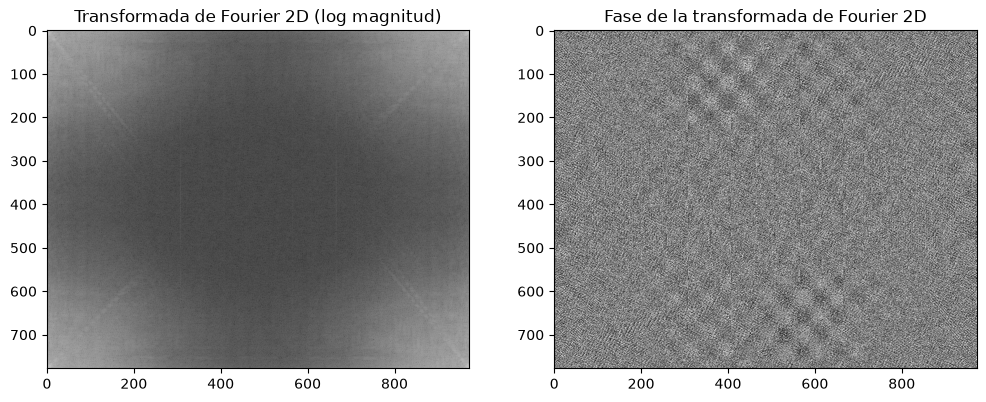

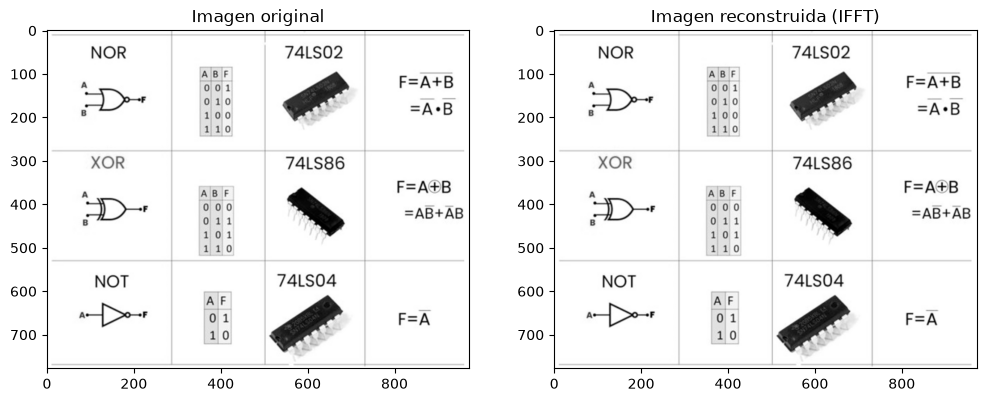

In [8]:
# Leyendo imagen y sacandole la transformada de fourier
from PIL import Image
img = Image.open(f"{project_root}/Sesiones/QC/figures/real_digital_circuits2.png").convert('L') # imagen random del github
fft2D = np.fft.fft2(img, s=None, axes=(-2, -1), norm=None)

# Grafica de la transformada 2D
plt.figure(figsize=(12,6))
plt.subplot(1,2,1)
plt.imshow(np.log(np.abs(fft2D)), cmap='gray')
plt.title("Transformada de Fourier 2D (log magnitud)")
plt.subplot(1,2,2)
plt.imshow(np.angle(fft2D), cmap='gray')
plt.title("Fase de la transformada de Fourier 2D")
plt.show()

# Reconsstrucción de la imagen usando inverse FFT 2D
img_reconstructed = np.fft.ifft2(fft2D).real

# Mostrando la imagen original y la reconstruida
plt.figure(figsize=(12,6))
plt.subplot(1,2,1)
plt.imshow(img, cmap='gray')
plt.title("Imagen original")
plt.subplot(1,2,2)
plt.imshow(img_reconstructed, cmap='gray')
plt.title("Imagen reconstruida (IFFT)")
plt.show()


2. Used the rutine created in class `FT(x,y)`. Modify it and do the FT to the signal. Do you get the same results?
3. Do the inverse FFT and reconstruc the original imagene. <br> Do you get a similar result? Compare the original and the reconstructed signal.

## NOTA: Como no se hizo un código exacto para la TF 2D en clase, busqué recursos y lo más similar que encontré fue este código en https://www.statology.org/how-to-implement-discrete-fourier-transform-with-numpy/, mi aproximación fue cambiar la suma que hacen en el código de la página por una integral con la función trapezoid para mejorar el tiempo computacional

Inversa en y: 100%|██████████| 973/973 [00:03<00:00, 298.25it/s]


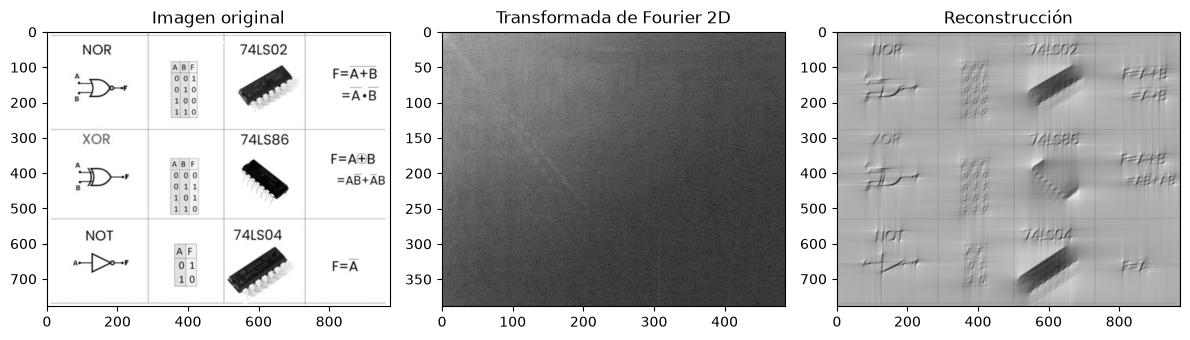

In [9]:
from tqdm import tqdm


def FT2D(f: np.array, kx: np.array, ky: np.array,
         dx: float, dy: float) -> np.array:
    """
    Calcula la TF bidimensional de una imagen
    mediante integración numérica por el método del trapecio.

    La TF 2D se define como: F(kx, ky) = dobleintegral (f(x, y) exp[-i 2*pi(kx*x + ky*y)]) dx dy
    """


    # Dimensiones de la imagen
    Nx, Ny = f.shape

    # Coordenadas espaciales
    x = np.arange(Nx) * dx
    y = np.arange(Ny) * dy

    # Transformada en x
    FT_x = np.zeros((len(kx), Ny), dtype=complex)

    for i, kxi in enumerate(tqdm(kx, desc="Transformada en x")):
        kernel_x = np.exp(-1j * 2 * np.pi * kxi * x)

        for j in range(Ny):
            FT_x[i, j] = np.trapezoid(f[:, j] * kernel_x, x) # trapezoid lo que hace es integrar usando el método del trapecio
                                                             # más rápido
    # Transformada en y
    FT_xy = np.zeros((len(kx), len(ky)), dtype=complex)

    for j, kyi in enumerate(tqdm(ky, desc="Transformada en y")):
        kernel_y = np.exp(-1j * 2 * np.pi * kyi * y) # integral de exp(-i 2*pi*ky*y) respecto a y

        for i in range(len(kx)):
            FT_xy[i, j] = np.trapezoid(FT_x[i, :] * kernel_y, y) # unión de las dos integrales, primero respecto a x y luego respecto a y

    return FT_xy

def IFT2D(F, kx, ky, x, y):
    """
    Calcula la TIF 2D como la integral doble de la TF:

    f(x, y) = integral doble(F(kx, ky) exp[i 2π(kx*x + ky*y)]) dkx dky
    """

    # Transformada inversa en kx
    IFT_x = np.zeros((len(x), len(ky)), dtype=complex)

    for i, xi in enumerate(tqdm(x, desc="Inversa en x")):
        kernel_x = np.exp(1j * 2 * np.pi * kx * xi) # la inversa se define como la integral de exp(i 2*pi*kx*x) respecto a x y y
        IFT_x[i, :] = np.trapezoid(F * kernel_x[:, np.newaxis], kx, axis=0)

    # Transformada inversa en ky
    IFT_xy = np.zeros((len(x), len(y)), dtype=complex)

    for j, yj in enumerate(tqdm(y, desc="Inversa en y")):
        kernel_y = np.exp(1j * 2 * np.pi * ky * yj)
        IFT_xy[:, j] = np.trapezoid(IFT_x * kernel_y[np.newaxis, :], ky, axis=1)

    return IFT_xy

img_array = np.array(img, dtype=float)
Nx, Ny = img_array.shape
dx = dy = 1
x, y = np.arange(Nx) * dx, np.arange(Ny) * dy
kx, ky = np.arange(Nx // 2) / (Nx * dx), np.arange(Ny // 2) / (Ny * dy)

FT2D_result = FT2D(img_array, kx, ky, dx, dy)
IFT2D_result = IFT2D(FT2D_result, kx, ky, x, y)

plt.figure(figsize=(12,6))

plt.subplot(1, 3, 1)
plt.imshow(img_array, cmap='gray')
plt.title("Imagen original")

plt.subplot(1, 3, 2)
plt.imshow(np.log1p(np.abs(FT2D_result)), cmap='gray')
plt.title("Transformada de Fourier 2D")

plt.subplot(1, 3, 3)
plt.imshow(np.real(IFT2D_result), cmap='gray')
plt.title("Reconstrucción")

plt.tight_layout()
plt.show()